In [4]:
import sys

!{sys.executable} -m pip install kagglehub

In [5]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download(
    "asaniczka/uk-optimal-product-price-prediction"
)

print("Dataset folder:", path)
print(os.listdir(path))

Dataset folder: /Users/andreazaffe/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3
['amz_uk_price_prediction_dataset.csv']


In [6]:
file_path = os.path.join(
    path,
    "amz_uk_price_prediction_dataset.csv"
)

df = pd.read_csv(file_path)

display(df.head())
print(df.shape)
print(df.columns.tolist())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


(2443651, 9)
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']


## Part 1: Best-Seller Trends Across Product Categories

We compare product categories with best-seller status to see whether some categories have a higher proportion of best-selling products.

In [7]:
# Create a crosstab showing the number of best-sellers
# and non-best-sellers in each category
best_seller_crosstab = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

# Rename the boolean columns to clearer text labels
best_seller_crosstab = best_seller_crosstab.rename(
    columns={
        False: "not_best_seller",
        True: "best_seller"
    }
)

# Calculate the total number of products in each category
best_seller_crosstab["total_products"] = (
    best_seller_crosstab["not_best_seller"]
    + best_seller_crosstab["best_seller"]
)

# Calculate the proportion of best-sellers per category
best_seller_crosstab["best_seller_proportion"] = (
    best_seller_crosstab["best_seller"]
    / best_seller_crosstab["total_products"]
)

# Sort from highest to lowest proportion
best_seller_crosstab = best_seller_crosstab.sort_values(
    by="best_seller_proportion",
    ascending=False
)

# Show the top 10 categories
best_seller_crosstab.head(10)

isBestSeller,not_best_seller,best_seller,total_products,best_seller_proportion
category,,,,
Grocery,9008,556,9564,0.058135
Smart Home Security & Lighting,98,6,104,0.057692
Health & Personal Care,9017,552,9569,0.057686
Mobile Phone Accessories,248,11,259,0.042471
Power & Hand Tools,8353,306,8659,0.035339
"Billiard, Snooker & Pool",241,8,249,0.032129
Pet Supplies,9152,285,9437,0.030200
Home Brewing & Wine Making,239,7,246,0.028455
Wind Instruments,243,7,250,0.028000


### Chi-square Test and Cramér's V

We test whether best-seller status is related to product category.  
The chi-square test checks whether the two variables are independent. Cramér's V measures how strong the relationship is.

In [8]:
from scipy.stats import chi2_contingency
import numpy as np

# Create a clean contingency table with counts only
contingency_table = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

# Run the chi-square test
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
rows, columns = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Cramér's V:", cramers_v)

Chi-square statistic: 36540.20270061387
P-value: 0.0
Degrees of freedom: 295
Cramér's V: 0.1222829439760564


### Further Investigation of the P-value

The p-value is displayed as 0.0 we therefore inspect the result using the chi-square survival function and the logarithm of the p-value.

In [9]:
from scipy.stats import chi2_contingency
from scipy.stats import chi2 as chi2_distribution

# Recreate the contingency table
contingency_table = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

# Recalculate the chi-square test using a new variable name
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

# Calculate the p-value with the survival function
p_value_sf = chi2_distribution.sf(chi2_stat, dof)

print("Chi-square statistic:", chi2_stat)
print("P-value:", p_value)
print(f"P-value in scientific notation: {p_value_sf:.10e}")
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
P-value: 0.0
P-value in scientific notation: 0.0000000000e+00
Degrees of freedom: 295


In [10]:
from scipy.stats import chi2

In [11]:
0.0000000000e+00

0.0

x### Stacked Bar Chart: Best-Seller Status by Category

The chart compares best-seller proportions across the 20 largest product categories.


In [12]:
import matplotlib.pyplot as plt

# Find the 20 categories with the highest number of products
top_20_categories = df["category"].value_counts().head(20).index


In [13]:
# Filter the dataset to the top 20 categories
top_20_df = df[df["category"].isin(top_20_categories)]

In [14]:
# Create a proportional crosstab
best_seller_proportions = pd.crosstab(
    top_20_df["category"],
    top_20_df["isBestSeller"],
    normalize="index"
)

In [15]:
# Rename the columns for clearer labels
best_seller_proportions = best_seller_proportions.rename(
    columns={
        False: "Not Best-Seller",
        True: "Best-Seller"
    }
)

In [16]:
# Sort categories by best-seller proportion
best_seller_proportions = best_seller_proportions.sort_values(
    by="Best-Seller",
    ascending=True
)

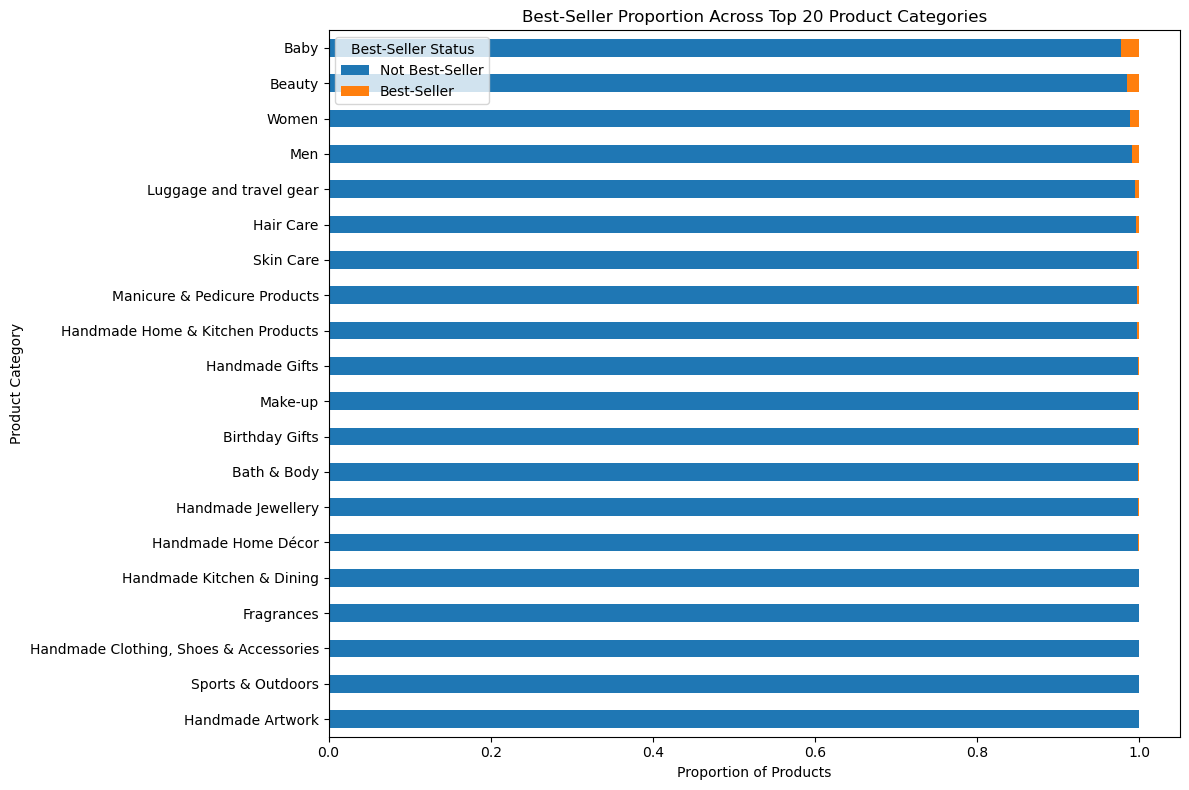

In [17]:
# Create the stacked horizontal bar chart
best_seller_proportions.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 8)
)

plt.title("Best-Seller Proportion Across Top 20 Product Categories")
plt.xlabel("Proportion of Products")
plt.ylabel("Product Category")
plt.legend(title="Best-Seller Status")
plt.tight_layout()
plt.show()

### Stacked Bar Chart Conclusion

Across the 20 largest product categories, most products are not classified as best-sellers. Baby and Beauty show slightly higher best-seller proportions than the other major categories, but the differences remain small.

This supports the statistical result: product category is related to best-seller status, but the relationship is weak.

## Part 2: Exploring Product Prices and Ratings Across Categories

Before comparing prices across categories, price outliers are removed using the IQR method. This prevents a small number of extremely expensive products from distorting the analysis.

In [18]:
# Calculate the first and third quartiles of product price
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 9.99
Q3: 45.99
IQR: 36.0


In [19]:
# Define the lower and upper limits for acceptable prices
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -44.01
Upper bound: 99.99000000000001


In [20]:
# Create a new dataframe without price outliers
df_no_outliers = df[
    (df["price"] >= lower_bound)
    & (df["price"] <= upper_bound)
].copy()

print("Original shape:", df.shape)
print("Shape without outliers:", df_no_outliers.shape)

Original shape: (2443651, 9)
Shape without outliers: (2115963, 9)


### Violin Plot: Price Distribution Across the Top 20 Categories

A violin plot shows both the spread and concentration of product prices. We use the 20 largest categories to keep the chart readable.

In [21]:
import seaborn as sns

# Identify the 20 categories with the most products
top_20_price_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

In [22]:
# Filter the cleaned dataframe to the top 20 categories
top_20_price_df = df_no_outliers[
    df_no_outliers["category"].isin(top_20_price_categories)
]

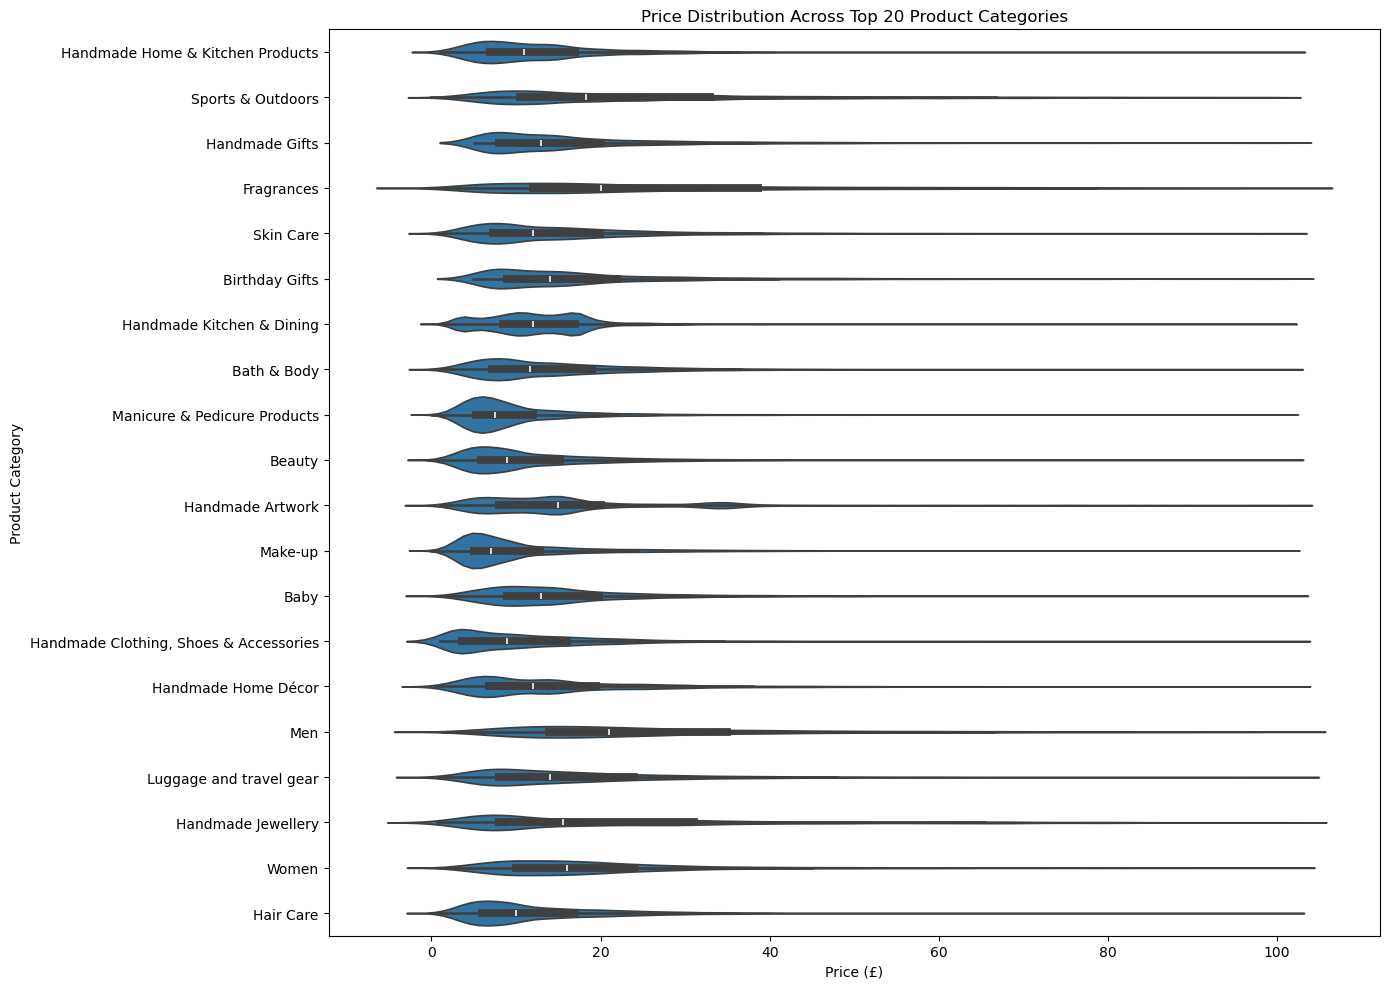

In [23]:
# Create the violin plot
plt.figure(figsize=(14, 10))

sns.violinplot(
    data=top_20_price_df,
    x="price",
    y="category"
)

plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Price (£)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

The width of each violin shows where product prices are most concentrated. Longer shapes indicate a wider price range within that category.

### Category With the Highest Median Price

We calculate the median price for every category using the dataset without price outliers.

In [24]:
# Calculate the median price for each category
median_price_by_category = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

# Display the 10 categories with the highest median prices
median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [25]:
# Identify the category with the highest median price
highest_median_category = median_price_by_category.index[0]
highest_median_price = median_price_by_category.iloc[0]

print("Category with highest median price:", highest_median_category)
print("Highest median price: £", round(highest_median_price, 2))

Category with highest median price: Desktop PCs
Highest median price: £ 74.0


### Median Price Conclusion

Desktop PCs have the highest median product price at £74.00. This suggests that products in this category are typically positioned at a higher price level than products in other categories, even after removing extreme price outliers.

### Average Price Across the Top 10 Product Categories

We compare the average product price across the 10 categories with the highest number of products.

In [26]:
# Identify the 10 categories with the most products
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

In [28]:
# Identify the 10 categories with the most products
top_10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

# Filter the data
top_10_price_df = df_no_outliers[
    df_no_outliers["category"].isin(top_10_categories)
]

In [29]:
mean_price_by_category = (
    df_no_outliers[
        df_no_outliers["category"].isin(top_10_categories)
    ]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

mean_price_by_category

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

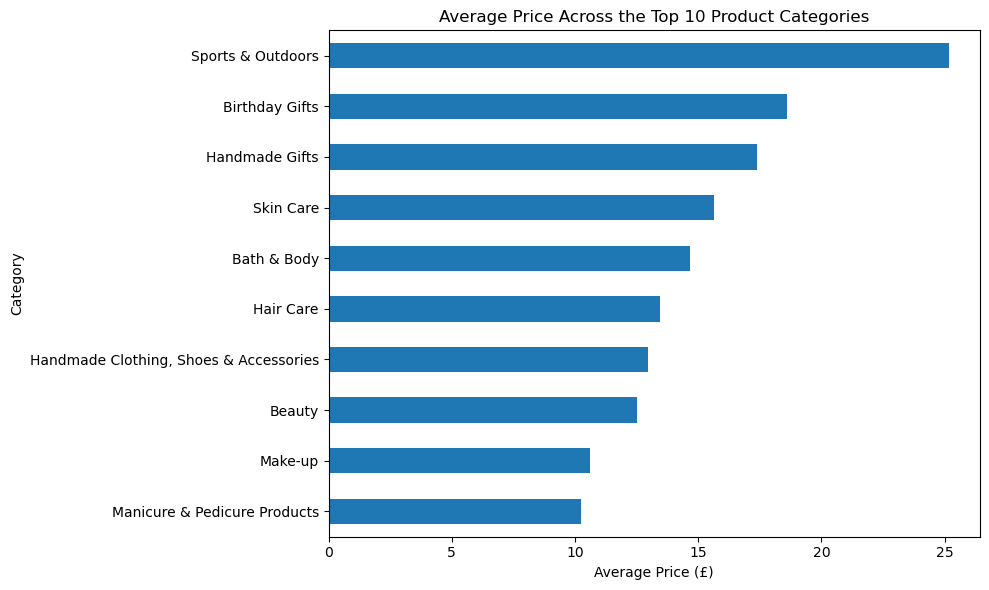

In [30]:
plt.figure(figsize=(10, 6))

mean_price_by_category.sort_values().plot(kind="barh")

plt.title("Average Price Across the Top 10 Product Categories")
plt.xlabel("Average Price (£)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

### Average Price Conclusion

Among the ten categories containing the most products, Sports & Outdoors has the highest average price at approximately £25.17. Manicure & Pedicure Products has the lowest average price at approximately £10.23.

This suggests that average prices differ considerably between product categories. However, this chart only describes the observed differences. It does not test whether those differences are statistically significant.